d:\Explainable-AI-CDSS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


Dataset Loaded Successfully!
Best Model Loaded Successfully!
SHAP Values Generated Successfully!


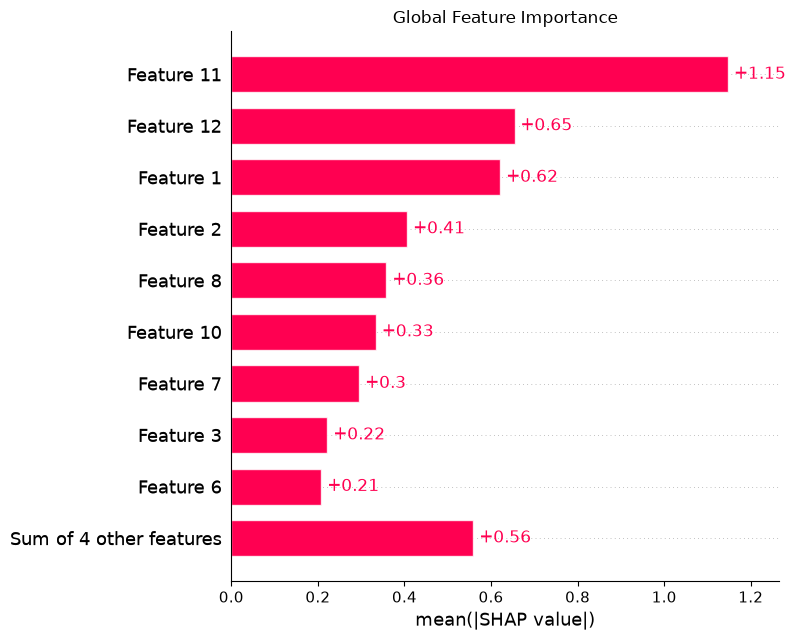

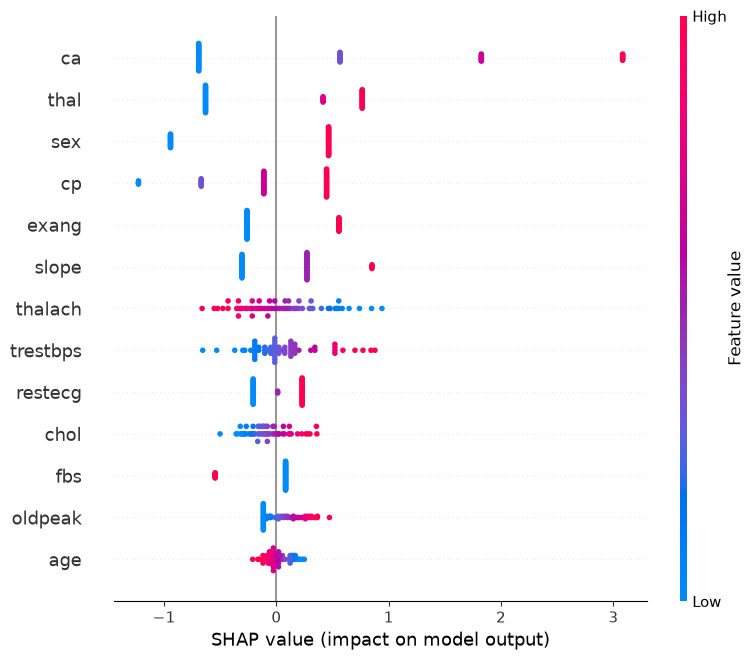

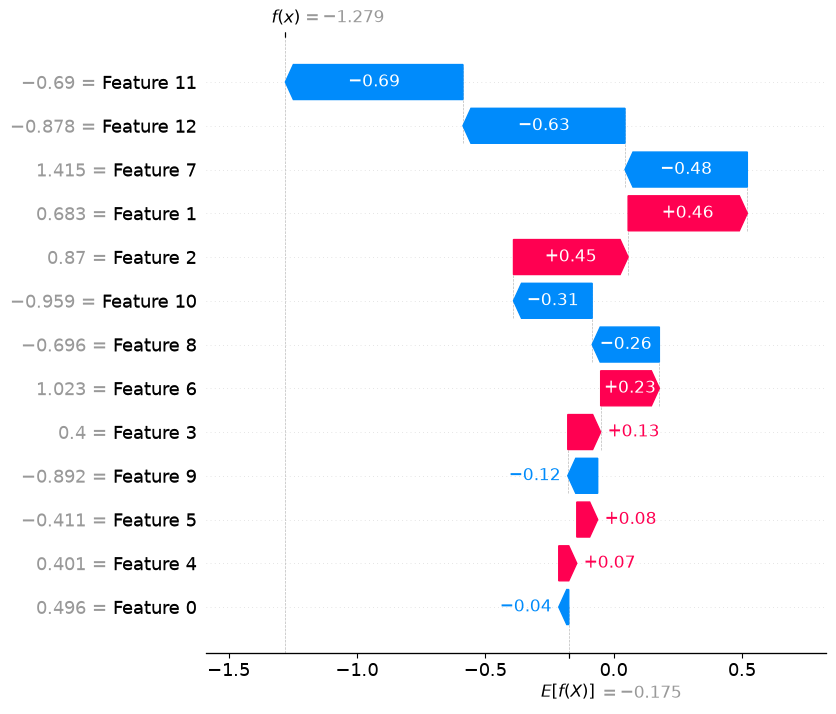


SHAP Analysis Completed Successfully!


In [2]:
# ==========================================
# SHAP EXPLAINABILITY
# ==========================================

# ==========================================
# Step 1: Import Libraries
# ==========================================

import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# ==========================================
# Step 2: Load Dataset
# ==========================================

df = pd.read_csv("../datasets/processed/heart_preprocessed.csv")

print("Dataset Loaded Successfully!")

# ==========================================
# Step 3: Separate Features and Target
# ==========================================

X = df.drop("target", axis=1)
y = df["target"]

# ==========================================
# Step 4: Train Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================
# Step 5: Load Scaler
# ==========================================

scaler = joblib.load("../models/scaler.pkl")

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# Step 6: Load Best Model
# ==========================================

model = joblib.load("../models/logistic_regression.pkl")

print("Best Model Loaded Successfully!")

# ==========================================
# Step 7: Create SHAP Explainer
# ==========================================

explainer = shap.Explainer(model, X_train_scaled)

# ==========================================
# Step 8: Generate SHAP Values
# ==========================================

shap_values = explainer(X_test_scaled)

print("SHAP Values Generated Successfully!")

# ==========================================
# Step 9: Global Feature Importance
# ==========================================

plt.figure(figsize=(10,6))

shap.plots.bar(
    shap_values,
    show=False
)

plt.title("Global Feature Importance")

plt.tight_layout()

plt.show()

# ==========================================
# Step 10: SHAP Summary Plot
# ==========================================

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X.columns
)

# ==========================================
# Step 11: Waterfall Plot
# ==========================================

shap.plots.waterfall(
    shap_values[0],
    max_display=13
)

# ==========================================
# Step 12: Force Plot
# ==========================================

shap.initjs()

shap.force_plot(
    explainer.expected_value,
    shap_values.values[0],
    X_test.iloc[0]
)

print("\nSHAP Analysis Completed Successfully!")